<a href="https://colab.research.google.com/github/lourdesdahianavera/proyecto-integrador-data3/blob/main/notebooks_pipeline_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Usando dispositivo: cuda
Epoch 01/20 | Train Loss: 0.6393 - Train Acc: 66.75% | Val Loss: 0.5798 - Val Acc: 79.50%
Epoch 02/20 | Train Loss: 0.5373 - Train Acc: 81.62% | Val Loss: 0.5004 - Val Acc: 84.50%
Epoch 03/20 | Train Loss: 0.4678 - Train Acc: 83.75% | Val Loss: 0.4428 - Val Acc: 87.00%
Epoch 04/20 | Train Loss: 0.4176 - Train Acc: 85.38% | Val Loss: 0.3975 - Val Acc: 88.00%
Epoch 05/20 | Train Loss: 0.3808 - Train Acc: 85.88% | Val Loss: 0.3679 - Val Acc: 88.00%
Epoch 06/20 | Train Loss: 0.3564 - Train Acc: 86.25% | Val Loss: 0.3474 - Val Acc: 88.00%
Epoch 07/20 | Train Loss: 0.3384 - Train Acc: 86.88% | Val Loss: 0.3361 - Val Acc: 88.00%
Epoch 08/20 | Train Loss: 0.3261 - Train Acc: 87.25% | Val Loss: 0.3248 - Val Acc: 88.00%
Epoch 09/20 | Train Loss: 0.3160 - Train Acc: 87.38% | Val Loss: 0.3187 - Val Acc: 89.00%
Epoch 10/20 | Train Loss: 0.3088 - Train Acc: 88.25% | Val Loss: 0.3138 - Val Acc: 89.50%
Epoch 11/20 | Train Loss: 0.3026 - Train Acc: 87.75% | Val Loss: 0.3096 - V

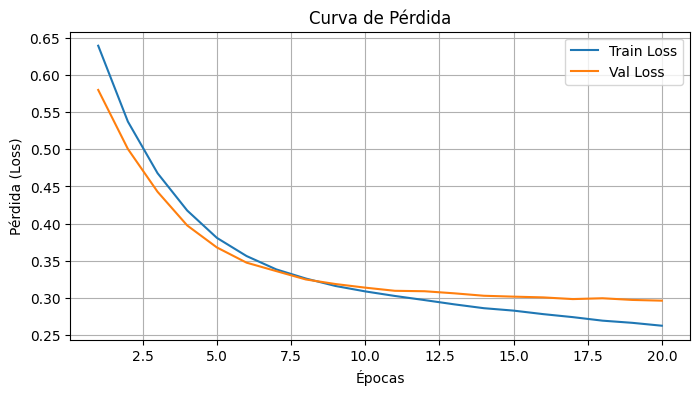

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Crear estructura de carpetas sugerida
os.makedirs("data", exist_ok=True)
os.makedirs("src", exist_ok=True)
os.makedirs("notebooks", exist_ok=True)

# 2. Detección automática de dispositivo
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Usando dispositivo: {device}")

# 3. Dataset sintético y preparación
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
val_dataset = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# 4. Definición de la arquitectura MLP
class MLPClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes):
        super(MLPClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.network(x)

model = MLPClassifier(input_dim=X_train.shape[1], hidden_dim=64, num_classes=2).to(device)

# 5. Configuración del optimizador y pérdida
learning_rate = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 6. Funciones de entrenamiento y evaluación
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)
    return running_loss / total, correct / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)
    return running_loss / total, correct / total

# 7. Loop principal
epochs = 20
train_losses, val_losses = [], []

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

# Guardar gráfico de pérdida
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), train_losses, label="Train Loss")
plt.plot(range(1, epochs+1), val_losses, label="Val Loss")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.title("Curva de Pérdida")
plt.legend()
plt.grid(True)
plt.savefig("loss_curve.png")
plt.show()

In [2]:
# Generar requirements.txt
with open("requirements.txt", "w") as f:
    f.write("torch>=2.0.0\nscikit-learn>=1.2.0\nmatplotlib>=3.7.0\n")

# Generar README.md
readme_content = """# Pipeline Base - Proyecto Integrador Data III

Infraestructura técnica inicial para el proyecto integrador.

## Estructura del Repositorio
- `data/`: Directorio para datasets iniciales.
- `notebooks/`: Cuadernos Jupyter con el flujo de entrenamiento.
- `src/`: Código fuente modular.
- `requirements.txt`: Dependencias del entorno.

## Checkpoint Técnico
- **Versión de PyTorch:** 2.x
- **Dispositivo:** Detección automática (GPU CUDA activa en Colab).
- **Modelo:** MLP (Multi-Layer Perceptron) con activación ReLU.
- **Hiperparámetros:** `learning_rate = 0.001`, `batch_size = 32`, `epochs = 20`, optimizador `Adam`.

## Interpretación de Resultados
La pérdida (`Loss`) descendió constantemente a lo largo de las 20 épocas, confirmando la convergencia del optimizador `Adam` mediante la retropropagación con `.backward()` de `torch.autograd`.
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("Archivos requirements.txt y README.md creados correctamente.")

Archivos requirements.txt y README.md creados correctamente.
